# Exercise I: K-Mean
Points A1–A9, K = 3, Euclidean distance, initial seeds A1, A4, A7.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

points = {"A1": (3, 8), "A2": (9, 4), "A3": (4, 9), "A4": (2, 2), "A5": (10, 5),
          "A6": (2, 4), "A7": (6, 8), "A8": (4, 3), "A9": (4, 7)}
names = list(points)
X = np.array(list(points.values()), dtype=float)
centroids = X[[0, 3, 6]]
colors = ["tab:red", "tab:green", "tab:blue"]

Iteration 1  (centroids used: [(3.0, 8.0), (2.0, 2.0), (6.0, 8.0)])
    dist2 to C1  dist2 to C2  dist2 to C3 cluster
A1          0.0         37.0          9.0      C1
A2         52.0         53.0         25.0      C3
A3          2.0         53.0          5.0      C1
A4         37.0          0.0         52.0      C2
A5         58.0         73.0         25.0      C3
A6         17.0          4.0         32.0      C2
A7          9.0         52.0          0.0      C3
A8         26.0          5.0         29.0      C2
A9          2.0         29.0          5.0      C1
  C1: members = ['A1', 'A3', 'A9'], new centroid = (3.67, 8.0)
  C2: members = ['A4', 'A6', 'A8'], new centroid = (2.67, 3.0)
  C3: members = ['A2', 'A5', 'A7'], new centroid = (8.33, 5.67)


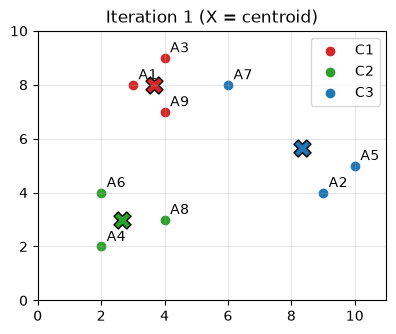

Iteration 2  (centroids used: [(3.67, 8.0), (2.67, 3.0), (8.33, 5.67)])
    dist2 to C1  dist2 to C2  dist2 to C3 cluster
A1         0.44        25.11        33.89      C1
A2        44.44        41.11         3.22      C3
A3         1.11        37.78        29.89      C1
A4        38.78         1.44        53.56      C2
A5        49.11        57.78         3.22      C3
A6        18.78         1.44        42.89      C2
A7         5.44        36.11        10.89      C1
A8        25.11         1.78        25.89      C2
A9         1.11        17.78        20.56      C1
  C1: members = ['A1', 'A3', 'A7', 'A9'], new centroid = (4.25, 8.0)
  C2: members = ['A4', 'A6', 'A8'], new centroid = (2.67, 3.0)
  C3: members = ['A2', 'A5'], new centroid = (9.5, 4.5)


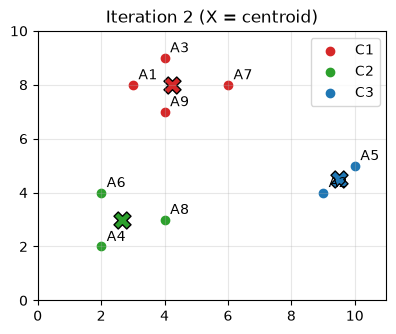

Iteration 3  (centroids used: [(4.25, 8.0), (2.67, 3.0), (9.5, 4.5)])
    dist2 to C1  dist2 to C2  dist2 to C3 cluster
A1         1.56        25.11         54.5      C1
A2        38.56        41.11          0.5      C3
A3         1.06        37.78         50.5      C1
A4        41.06         1.44         62.5      C2
A5        42.06        57.78          0.5      C3
A6        21.06         1.44         56.5      C2
A7         3.06        36.11         24.5      C1
A8        25.06         1.78         32.5      C2
A9         1.06        17.78         36.5      C1
  C1: members = ['A1', 'A3', 'A7', 'A9'], new centroid = (4.25, 8.0)
  C2: members = ['A4', 'A6', 'A8'], new centroid = (2.67, 3.0)
  C3: members = ['A2', 'A5'], new centroid = (9.5, 4.5)


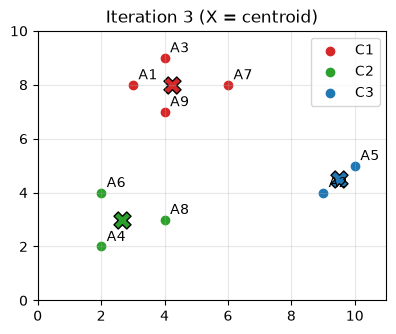

Converged after 3 iterations


In [2]:
iteration = 0
while True:
    iteration += 1
    dist2 = ((X[:, None, :] - centroids) ** 2).sum(axis=2)
    labels = dist2.argmin(axis=1)
    new_centroids = np.array([X[labels == k].mean(axis=0) for k in range(3)])

    table = pd.DataFrame(dist2, index=names, columns=[f"dist2 to C{k+1}" for k in range(3)]).round(2)
    table["cluster"] = [f"C{l+1}" for l in labels]
    print(f"Iteration {iteration}  (centroids used: {[tuple(c.round(2).tolist()) for c in centroids]})")
    print(table.to_string())
    for k in range(3):
        members = [n for n, l in zip(names, labels) if l == k]
        print(f"  C{k+1}: members = {members}, new centroid = {tuple(new_centroids[k].round(2).tolist())}")

    fig, ax = plt.subplots(figsize=(4.5, 3.5))
    for k in range(3):
        ax.scatter(*X[labels == k].T, c=colors[k], label=f"C{k+1}")
        ax.scatter(*new_centroids[k], c=colors[k], marker="X", s=150, edgecolors="k")
    for n, (x, y) in points.items():
        ax.annotate(n, (x, y), xytext=(4, 4), textcoords="offset points")
    ax.set_title(f"Iteration {iteration} (X = centroid)")
    ax.set_xlim(0, 11); ax.set_ylim(0, 10); ax.legend(); ax.grid(alpha=0.3)
    plt.show()

    if np.allclose(new_centroids, centroids):
        break
    centroids = new_centroids
print(f"Converged after {iteration} iterations")

## Answer
| Iteration | C1 members / centroid | C2 members / centroid | C3 members / centroid |
|---|---|---|---|
| 1 | A1, A3, A9 / (3.67, 8) | A4, A6, A8 / (2.67, 3) | A2, A5, A7 / (8.33, 5.67) |
| 2 | A1, A3, A7, A9 / (4.25, 8) | A4, A6, A8 / (2.67, 3) | A2, A5 / (9.5, 4.5) |
| 3 | A1, A3, A7, A9 / (4.25, 8) | A4, A6, A8 / (2.67, 3) | A2, A5 / (9.5, 4.5) |

K-Means converges after 3 iterations (iteration 3 gives no change in members or centroids).

Final clusters: C1 = {A1, A3, A7, A9}, centroid (4.25, 8); C2 = {A4, A6, A8}, centroid (2.67, 3); C3 = {A2, A5}, centroid (9.5, 4.5).